# Readmission study

Exploratory analysis of synthetic hospital admissions data. Worked example to get used to integration of SQL, python (in particular venv) and using AI coding.


## Import libraries

In [52]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
from src.db_config import DATABASE_URL

## Connect to database

In [53]:
engine = create_engine(DATABASE_URL)

## Patient demographics

In [54]:
query = """
WITH reference_date AS (
    SELECT MAX(discharge_date) AS reference_date
    FROM admissions
)
SELECT
    p.patient_id,
    p.sex,
    p.dob,
    r.reference_date,
    EXTRACT(YEAR FROM AGE(r.reference_date, p.dob))::INT
        AS age_at_reference_date
FROM patients AS p
CROSS JOIN reference_date AS r
ORDER BY p.patient_id
"""

In [55]:
df_demographics = pd.read_sql(query, engine)
df_demographics

,patient_id,sex,dob,reference_date,age_at_reference_date
0,1,Female,1981-05-13,2024-11-28,43
1,2,Male,1926-03-30,2024-11-28,98
2,3,Female,1945-12-20,2024-11-28,78
3,4,Female,1936-07-08,2024-11-28,88
4,5,Female,1984-09-16,2024-11-28,40
...,...,...,...,...,...
995,996,Female,2005-12-15,2024-11-28,18
996,997,Male,1947-06-26,2024-11-28,77
997,998,Male,1987-02-28,2024-11-28,37
998,999,Male,1943-04-02,2024-11-28,81


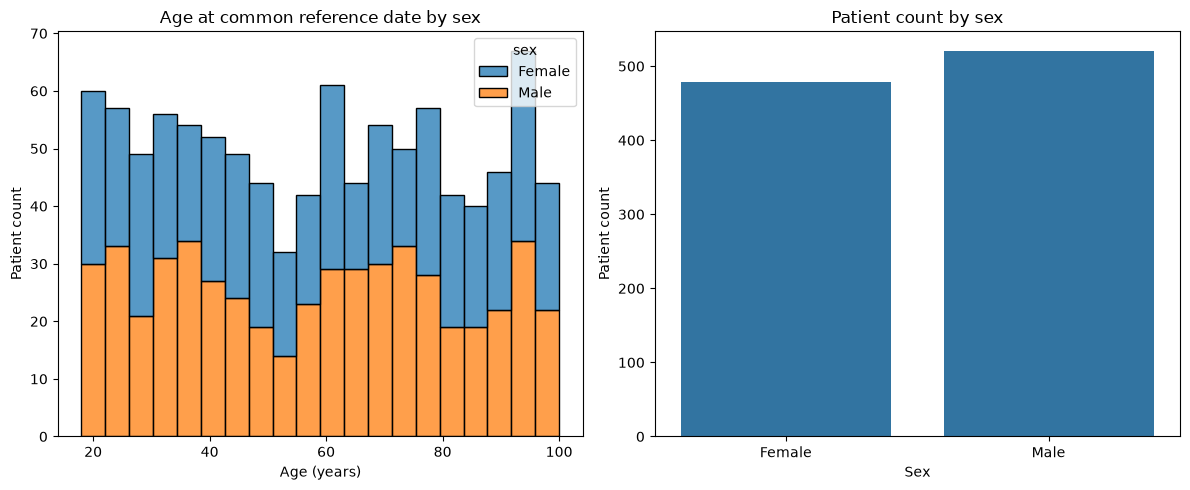

In [56]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(
    data=df_demographics,
    x="age_at_reference_date",
    hue="sex",
    bins=20,
    multiple="stack",
    ax=axes[0]
)
axes[0].set_title("Age at common reference date by sex")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Patient count")

sns.countplot(data=df_demographics, x="sex", ax=axes[1])
axes[1].set_title("Patient count by sex")
axes[1].set_xlabel("Sex")
axes[1].set_ylabel("Patient count")

fig.tight_layout()

## Average length of stay by diagnosis

In [41]:
query = """
SELECT
    diagnosis,
    AVG(discharge_date - admission_date) AS avg_los
FROM admissions
GROUP BY diagnosis
ORDER BY avg_los DESC
"""


In [ ]:
df = pd.read_sql(query, engine) 
df

,diagnosis,avg_los
0,Chest pain,7.743003
1,Kidney disease,7.693966
2,Type 2 diabetes,7.521318
3,Heart failure,7.501114
4,Sepsis,7.500000
5,Chronic obstructive pulmonary disease,7.458824
6,Hip fracture,7.408034
7,Urinary tract infection,7.369710
8,Stroke,7.358209
9,Pneumonia,7.279176


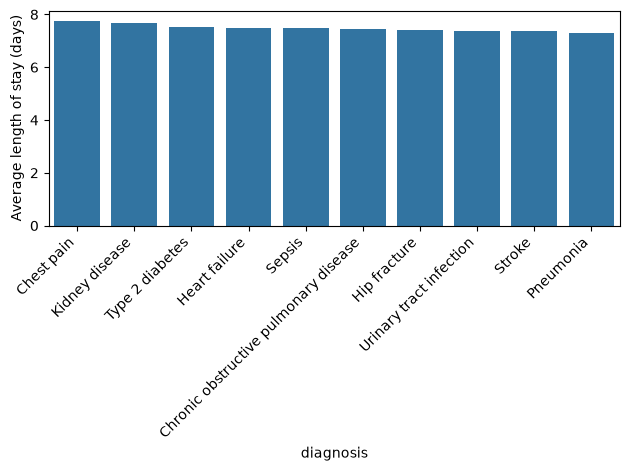

In [44]:


ax = sns.barplot(
    data=df,
    x="diagnosis",
    y="avg_los"
)
ax.set_ylabel("Average length of stay (days)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

## First diagnosis per patient and disease

In [45]:
first_diagnoses_query = """
WITH ranked_admissions AS (
    SELECT
        a.patient_id,
        a.diagnosis,
        a.admission_date AS first_diagnosis_date,
        p.dob,
        ROW_NUMBER() OVER (
            PARTITION BY a.patient_id, a.diagnosis
            ORDER BY a.admission_date, a.admission_id
        ) AS diagnosis_rank
    FROM admissions AS a
    JOIN patients AS p ON a.patient_id = p.patient_id
)
SELECT patient_id, diagnosis, first_diagnosis_date, dob
FROM ranked_admissions
WHERE diagnosis_rank = 1
ORDER BY patient_id, first_diagnosis_date, diagnosis
"""

In [46]:
df_first_diagnoses = pd.read_sql(first_diagnoses_query, engine)
df_first_diagnoses

,patient_id,diagnosis,first_diagnosis_date,dob
0,1,Type 2 diabetes,2019-05-18,1981-05-13
1,1,Heart failure,2019-12-30,1981-05-13
2,2,Chronic obstructive pulmonary disease,2021-04-04,1926-03-30
3,2,Type 2 diabetes,2021-05-14,1926-03-30
4,2,Heart failure,2021-09-30,1926-03-30
...,...,...,...,...
2978,1000,Pneumonia,2020-05-04,1986-04-05
2979,1000,Chronic obstructive pulmonary disease,2020-05-22,1986-04-05
2980,1000,Urinary tract infection,2021-03-24,1986-04-05
2981,1000,Sepsis,2021-04-24,1986-04-05


## Average age by first diagnosis

In [47]:
df_first_diagnoses["dob"] = pd.to_datetime(df_first_diagnoses["dob"])
df_first_diagnoses["first_diagnosis_date"] = pd.to_datetime(
    df_first_diagnoses["first_diagnosis_date"]
)

df_first_diagnoses["age_at_diagnosis"] = (
    (df_first_diagnoses["first_diagnosis_date"] - df_first_diagnoses["dob"])
    .dt.days / 365.25
) 

In [48]:
avg_age_by_first_diagnosis = (
    df_first_diagnoses.groupby("diagnosis", as_index=False)["age_at_diagnosis"]
    .mean()
    .rename(columns={"age_at_diagnosis": "avg_age"})
    .sort_values("avg_age", ascending=False)
)
avg_age_by_first_diagnosis

,diagnosis,avg_age
1,Chronic obstructive pulmonary disease,59.125415
8,Type 2 diabetes,57.567339
7,Stroke,56.005486
0,Chest pain,55.465831
2,Heart failure,55.324864
3,Hip fracture,55.151345
5,Pneumonia,54.929014
4,Kidney disease,54.901236
9,Urinary tract infection,53.677135
6,Sepsis,53.587110


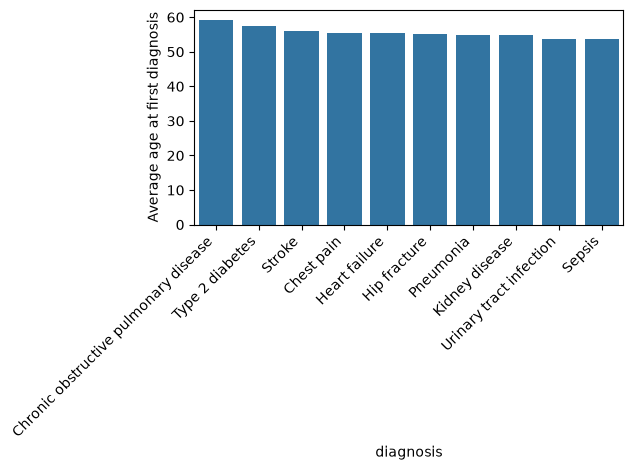

In [49]:
ax = sns.barplot(
    data=avg_age_by_first_diagnosis,
    x="diagnosis",
    y="avg_age"
)
ax.set_ylabel("Average age at first diagnosis")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

## Readmission
ground truth readmission reason

In [58]:
query = """
SELECT
    readmission_reason,
    COUNT(*) AS readmission_count
FROM admissions
GROUP BY readmission_reason
ORDER BY readmission_count DESC
"""
df = pd.read_sql(query, engine) 
df

,readmission_reason,readmission_count
0,new_episode,2196
1,index_admission,1000
2,unplanned_related,535
3,unplanned_unrelated,363
4,planned_follow_up,356


defining readmission as within 30 days

In [67]:
query = """
WITH admissions_with_prev AS (
    SELECT
        admission_id,
        patient_id,
        admission_date,
        discharge_date,
        diagnosis,

        LAG(discharge_date) OVER (
            PARTITION BY patient_id
            ORDER BY admission_date
        ) AS previous_discharge_date

    FROM admissions
)

SELECT
    *,
        admission_date - previous_discharge_date AS days_since_last_discharge,
    CASE
        WHEN previous_discharge_date IS NOT NULL
         AND admission_date - previous_discharge_date <= 30
        THEN 1
        ELSE 0
    END AS readmission_30d

FROM admissions_with_prev;
"""

df = pd.read_sql(query, engine) 
df["readmission_30d"].value_counts()

readmission_30d
0    3196
1    1254
Name: count, dtype: int64

In [68]:
df

,admission_id,patient_id,admission_date,discharge_date,diagnosis,previous_discharge_date,days_since_last_discharge,readmission_30d
0,469,1,2019-05-18,2019-06-01,Type 2 diabetes,None,NaN,0
1,494,1,2019-06-07,2019-06-19,Type 2 diabetes,2019-06-01,6.0,1
2,820,1,2019-12-30,2020-01-10,Heart failure,2019-06-19,194.0,0
3,843,1,2020-01-13,2020-01-22,Heart failure,2020-01-10,3.0,1
4,1581,2,2021-04-04,2021-04-18,Chronic obstructive pulmonary disease,None,NaN,0
...,...,...,...,...,...,...,...,...
4445,1033,1000,2020-05-22,2020-05-31,Chronic obstructive pulmonary disease,2020-05-12,10.0,1
4446,1555,1000,2021-03-24,2021-04-03,Urinary tract infection,2020-05-31,297.0,0
4447,1623,1000,2021-04-24,2021-04-28,Sepsis,2021-04-03,21.0,1
4448,1822,1000,2021-08-07,2021-08-18,Hip fracture,2021-04-28,101.0,0
